# Miscancelaneous computations

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os
import myfunctions
import h5py


SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24

## Computing OTFS

In [ ]:
D = 17.5e-3  # [m]
wl = 632.8e-9  # [m]
pad = 2
dx = 3.928571e-06

with h5py.File("dataInputs/ao_ipsf_test_1.h5", 'r') as temp:
            key = list(temp.keys())
            ipsf = temp[key[0]][()][:]

with h5py.File("dataInputs/ipsf_difflim.h5", 'r') as temp:
            ipsf_difflim = temp[list(temp.keys())[0]][()]

padded_ipsf = myfunctions.pad_center(ipsf, pad)
padded_ipsf_difflim = myfunctions.pad_center(ipsf_difflim, pad)
OTF_diff_lim = np.abs(myfunctions.otf_from_psf(padded_ipsf_difflim))


N = ipsf_difflim.shape[1]*pad
fc = D / wl
freq = np.fft.fftshift(np.fft.fftfreq(N, d=dx))
freq_n = np.abs(freq) / fc
NU_X, NU_Y = np.meshgrid(freq_n, freq_n)
nu_n_grid = np.sqrt(NU_X**2 + NU_Y**2)
# FREQ_MASK = np.abs(freq) < fc
FREQ_MASK = nu_n_grid < 1


OTF_diff_lim = np.abs(myfunctions.otf_from_psf(padded_ipsf_difflim))
OTF_tel = myfunctions.telescope_otf(nu_n_grid)
OTF_aliasing = OTF_diff_lim - OTF_tel

# OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:] - OTF_aliasing)*FREQ_MASK
# OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:])*FREQ_MASK
OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:])


In [ ]:
therandom = np.random.randint(0, OTFs.shape[0])
print(therandom)
plt.figure(figsize=(10, 8))
plt.plot(freq, OTF_tel[N//2, :], ".-b", label="Theoretical diffraction-limited OTF")
plt.plot(freq, OTF_diff_lim[N//2, :], "k", linestyle="dotted", label="Diffraction-limited OTF\nfrom simulated PSF with aliasing")
plt.plot(freq, OTF_aliasing[N//2, :],"--.",label = "Aliasing OTF")
plt.plot(freq, OTFs[therandom,N//2, :],"--k", label="Measured OTF without aliasing")
plt.plot(freq, OTF_diff_lim[N//2, :]-OTF_aliasing[N//2, :], "--.k", label="Diffraction-limited OTF\nfrom simulated PSF without aliasing")
plt.vlines([-fc, fc], 0, 1, "k", linestyles=[(0, (1, 10))], label = r"$\pm$ cutoff frequency")
plt.title(f"Diffraction limited and randomly\nselected OTFs (N°{therandom})", fontsize = 22)
plt.xlabel("Angular frequency [cycles/meter]", fontsize=18)
plt.ylabel("OTF", fontsize=18)
plt.xlim([-fc * 1.2, fc * 1.2])
plt.ylim([0, 1])
plt.xticks(fontsize=18*.8)
plt.yticks(fontsize=18*.8)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=18)
plt.tight_layout()

In [3]:
with h5py.File("dataInputs/ao_iOTF_test_"+str(1)+".h5", "w") as f:
    f.create_dataset("iOTF", data=OTFs)

In [4]:
with h5py.File("dataInputs/ao_ipsf_val_1.h5", 'r') as temp:
            key = list(temp.keys())
            ipsf = temp[key[0]][()][:]

padded_ipsf = myfunctions.pad_center(ipsf, pad)

# OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:] - OTF_aliasing)*FREQ_MASK
OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:] )

with h5py.File("dataInputs/ao_iOTF_val_"+str(1)+".h5", "w") as f:
    f.create_dataset("iOTF", data=OTFs)

In [5]:
with h5py.File("dataInputs/ao_ipsf_train_1.h5", 'r') as temp:
            key = list(temp.keys())
            ipsf = temp[key[0]][()][:]

padded_ipsf = myfunctions.pad_center(ipsf, pad)

# OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:] - OTF_aliasing)*FREQ_MASK
OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:])

with h5py.File("dataInputs/ao_iOTF_train_"+str(1)+".h5", "w") as f:
    f.create_dataset("iOTF", data=OTFs)

# Showing pupil illumination

In [3]:
with h5py.File("output_prep/ao_intensity_map_test_1.h5", 'r') as temp:
            key = list(temp.keys())
            ipsf = temp[key[0]][()][:]

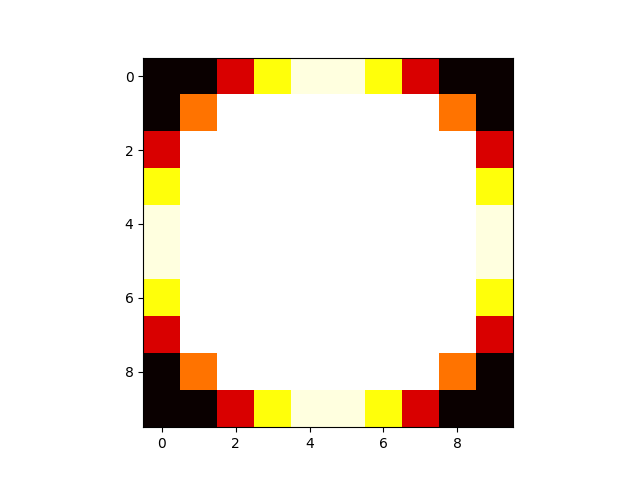

In [ ]:
plt.figure()
plt.imshow(ipsf[8,:, :], cmap="hot")

# Compiling trainig/validation loss

In [2]:
folders = ["WFSxy", "WFSxy_DM", "WFSxy_intensity", "WFSxy_DM_intensity", "WFSxy_DM_intensity_otf", "lightfield", "lightfield_DM", ]
datasets = ["WFSxy", "WFSxy and DM commands", "WFSxy and intensity", "WFSxy and DM commands and intensity", "WFSxy and DM commands and intensity for OTF", "Lightfield", "Lightfield and DM commands"]
Epochs = 100

training_loss = np.zeros((len(folders), Epochs))
validation_loss = np.zeros((len(folders), Epochs))

for i in range(len(folders)):
    with h5py.File("output_ML/" + folders[i] + "/history.h5", 'r') as temp:
        key = list(temp.keys())
        training_loss[i] = temp['loss'][()][:]
        validation_loss[i] = temp['val_loss'][()][:]


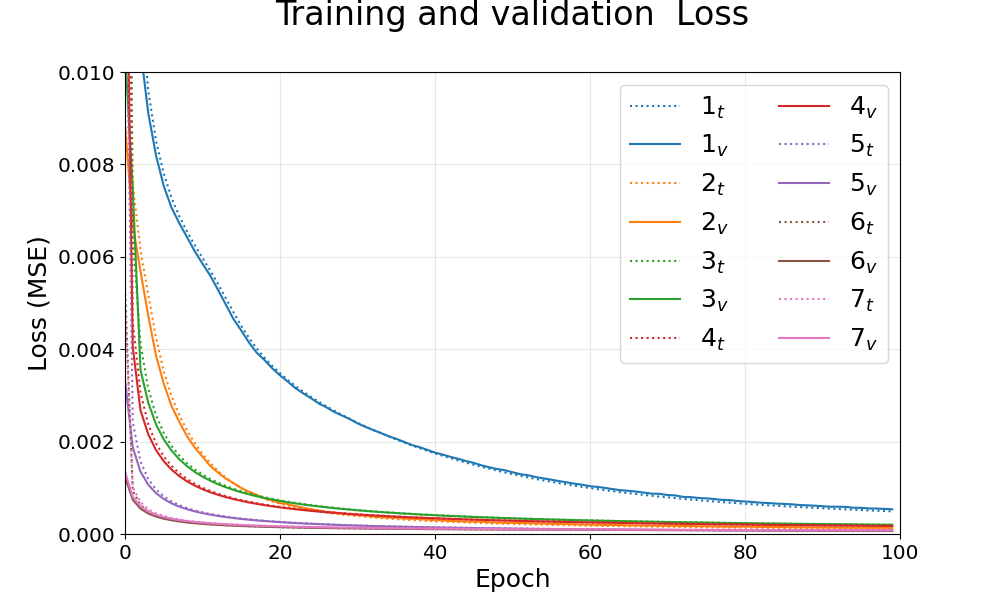

In [3]:
plt.close(0)
x = np.linspace(0, Epochs-1, Epochs)
plt.figure(0,figsize=(10, 6))
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
plt.plot(x, training_loss[0], ":", color = colors[0], label=r"$1_t$")
plt.plot(x, validation_loss[0], color = colors[0], label=r"$1_v$")
plt.plot(x, training_loss[1], ":", color = colors[1], label=r"$2_t$")
plt.plot(x, validation_loss[1], color = colors[1], label=r"$2_v$")
plt.plot(x, training_loss[2], ":", color = colors[2], label=r"$3_t$")
plt.plot(x, validation_loss[2], color = colors[2], label=r"$3_v$")
plt.plot(x, training_loss[3], ":", color = colors[3], label=r"$4_t$")
plt.plot(x, validation_loss[3], color = colors[3], label=r"$4_v$")
plt.plot(x, training_loss[4], ":", color = colors[4], label=r"$5_t$")
plt.plot(x, validation_loss[4], color = colors[4], label=r"$5_v$")
plt.plot(x, training_loss[5], ":", color = colors[5], label=r"$6_t$")
plt.plot(x, validation_loss[5], color = colors[5], label=r"$6_v$")
plt.plot(x, training_loss[6], ":", color = colors[6], label=r"$7_t$")
plt.plot(x, validation_loss[6], color = colors[6], label=r"$7_v$")

plt.title(f"Training and validation  Loss\n", fontsize = BIGGER_SIZE)
plt.xlabel("Epoch", fontsize=SMALL_SIZE)
plt.ylabel("Loss (MSE)", fontsize=SMALL_SIZE)
plt.xlim([0, 100])
plt.ylim([0, 0.01])
plt.xticks(fontsize=SMALL_SIZE*.8)
plt.yticks(fontsize=SMALL_SIZE*.8)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=SMALL_SIZE, ncol=2)
# plt.tight_layout()

# plt.figure(figsize=(10, 8))

# Model summary

In [37]:
import torch
from torchinfo import summary
import TM26_unet as unet
model = unet.build_unet(input_shape=(160, 160, 4), n_channels_out=1) # input shape is (width, height, channel) where channel is WFSx, WFSy and intensity

summary(model, input_size=(1, 4, 160, 160))

Layer (type:depth-idx)                        Output Shape              Param #
UNet                                          [1, 1, 160, 160]          --
├─DoubleConv: 1-1                             [1, 64, 160, 160]         --
│    └─Sequential: 2-1                        [1, 64, 160, 160]         --
│    │    └─Conv2d: 3-1                       [1, 64, 160, 160]         2,368
│    │    └─BatchNorm2d: 3-2                  [1, 64, 160, 160]         128
│    │    └─ReLU: 3-3                         [1, 64, 160, 160]         --
│    │    └─Conv2d: 3-4                       [1, 64, 160, 160]         36,928
│    │    └─BatchNorm2d: 3-5                  [1, 64, 160, 160]         128
│    │    └─ReLU: 3-6                         [1, 64, 160, 160]         --
├─Down: 1-2                                   [1, 128, 80, 80]          --
│    └─Sequential: 2-2                        [1, 128, 80, 80]          --
│    │    └─MaxPool2d: 3-7                    [1, 64, 80, 80]           --
│    │    └